# Тренувальний ноутбук: лінійна регресія та регуляризація

**Курс:** Машинне навчання
**Тема:** Linear Regression, Ridge, Lasso, Elastic Net

Цей ноутбук відповідає лекції про лінійну регресію та побудований як практичне продовження теоретичного матеріалу. У прикладах послідовно розглядаються проста й множинна лінійна регресія, метрики, залишки, недонавчання і перенавчання, L1/L2-регуляризація, Ridge, Lasso, Elastic Net, масштабування, крос-валідація, GridSearchCV, Pipeline, ColumnTransformer та навчальні криві.

У ноутбуці є два типи комірок:

* **Приклад** — готовий код, який потрібно виконати, проаналізувати та пояснити.
* **Самостійне завдання** — окрема кодова комірка з позначкою TODO. Її потрібно заповнити власноруч. Готового розв'язку в ноутбуці немає.

**Рекомендація:** виконувати комірки послідовно зверху вниз і після кожного блоку формулювати короткий висновок своїми словами.

## 0. Імпорт бібліотек і налаштування середовища

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Середовище готове до роботи.')

Середовище готове до роботи.


## 1. Проста лінійна регресія

Для однієї ознаки модель має вигляд

$$\hat y = b_0 + b_1 x.$$

Тут $b_0$ — вільний член, а $b_1$ показує, на скільки одиниць у середньому змінюється прогноз $\hat y$ при збільшенні $x$ на одну одиницю.

Нижче згенеруємо дані, у яких істинна залежність приблизно дорівнює $y = 5 + 2.4x$, але спостереження містять випадковий шум.

Вільний член b0: 4.907
Коефіцієнт b1: 2.451


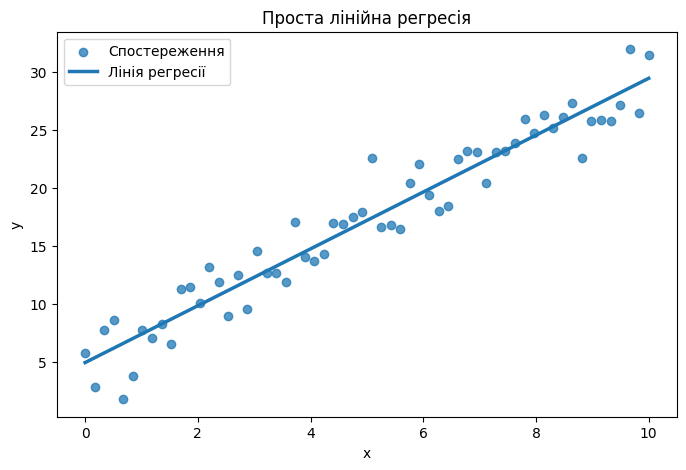

In [6]:
rng = np.random.default_rng(RANDOM_STATE)

X_simple = np.linspace(0, 10, 60).reshape(-1, 1)
y_simple = 5 + 2.4 * X_simple.ravel() + rng.normal(0, 2.5, size=len(X_simple))

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)
y_simple_pred = simple_model.predict(X_simple)

print(f'Вільний член b0: {simple_model.intercept_:.3f}')
print(f'Коефіцієнт b1: {simple_model.coef_[0]:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(X_simple.ravel(), y_simple, alpha=0.75, label='Спостереження')
plt.plot(X_simple.ravel(), y_simple_pred, linewidth=2.5, label='Лінія регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Проста лінійна регресія')
plt.legend()
plt.show()

**Що потрібно побачити.** Коефіцієнт нахилу має бути близьким до 2.4, але не обов'язково дорівнювати йому точно, оскільки дані містять шум. `fit()` оцінює параметри за навчальними даними, а `predict()` лише обчислює прогноз для заданих значень ознак.

### Самостійне завдання 1

1. Створіть новий масив `X_new` зі значеннями 2, 5 і 8.
2. Отримайте прогнози моделі.
3. Виведіть таблицю з колонками `x` та `prediction`.
4. Одним реченням поясніть зміст отриманого коефіцієнта $b_1$.

In [7]:
X_new = np.array([2, 5, 8]).reshape(-1, 1)
predictions = simple_model.predict(X_new)

task1_table = pd.DataFrame({
    'x': X_new.ravel(),
    'prediction': predictions
})
display(task1_table)

,x,prediction
0,2,9.809730
1,5,17.163214
2,8,24.516697


**Пояснення $b_1$:** коефіцієнт b1 ≈ 2.45 означає, що при збільшенні x на одну одиницю прогноз ŷ у середньому зростає приблизно на 2.45 (це близько до істинного значення 2.4, а невелика різниця виникає через випадковий шум у даних).

## 2. Метод найменших квадратів і ручний розрахунок коефіцієнтів

Для простої регресії коефіцієнт нахилу можна обчислити без готової моделі:

$$b_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}, \qquad b_0 = \bar y - b_1 \bar x.$$

Чисельник у формулі для $b_1$ відображає спільну зміну $x$ і $y$, а знаменник — варіативність самої ознаки $x$. Після знаходження нахилу вільний член підбирається так, щоб пряма проходила через точку $(\bar x, \bar y)$.

In [8]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3.0, 5.2, 6.8, 9.1, 10.9])

x_bar = x.mean()
y_bar = y.mean()

b1_manual = ((x - x_bar) * (y - y_bar)).sum() / ((x - x_bar) ** 2).sum()
b0_manual = y_bar - b1_manual * x_bar

model_check = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={model_check.intercept_:.4f}, b1={model_check.coef_[0]:.4f}')

Ручний розрахунок: b0=1.0900, b1=1.9700
scikit-learn:     b0=1.0900, b1=1.9700


### Самостійне завдання 2

Використайте масиви `x2 = [2, 4, 6, 8, 10]` та `y2 = [7, 11, 16, 19, 25]`. Власноруч обчисліть $b_0$ і $b_1$ за формулами, а потім перевірте результат за допомогою `LinearRegression`.

In [9]:
x2 = np.array([2, 4, 6, 8, 10], dtype=float)
y2 = np.array([7, 11, 16, 19, 25], dtype=float)

x2_bar = x2.mean()
y2_bar = y2.mean()

b1_2 = ((x2 - x2_bar) * (y2 - y2_bar)).sum() / ((x2 - x2_bar) ** 2).sum()
b0_2 = y2_bar - b1_2 * x2_bar

check2 = LinearRegression().fit(x2.reshape(-1, 1), y2)

print(f'x_bar = {x2_bar}, y_bar = {y2_bar}')
print(f'Ручний розрахунок: b0={b0_2:.4f}, b1={b1_2:.4f}')
print(f'scikit-learn:     b0={check2.intercept_:.4f}, b1={check2.coef_[0]:.4f}')
print('Збігаються:', np.isclose(b0_2, check2.intercept_) and np.isclose(b1_2, check2.coef_[0]))

x_bar = 6.0, y_bar = 15.6
Ручний розрахунок: b0=2.4000, b1=2.2000
scikit-learn:     b0=2.4000, b1=2.2000
Збігаються: True


**Висновок:** обчислені вручну значення b0 = 2.4 і b1 = 2.2 (x̄ = 6, ȳ = 15.6) збігаються з результатом LinearRegression, тобто модель має вигляд ŷ = 2.4 + 2.2·x: при зростанні x на 1 прогноз у середньому зростає на 2.2.

## 3. Множинна лінійна регресія

У випадку кількох ознак модель має вигляд

$$\hat y = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_p x_p.$$

Коефіцієнт $b_j$ інтерпретується як зміна прогнозу при збільшенні ознаки $x_j$ на одну одиницю **за інших рівних умов**, тобто при фіксованих значеннях інших ознак.

Для практики використаємо вбудований набір `diabetes`, тому ноутбук не потребує завантаження даних з Інтернету.

In [10]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())

Розмір X: (442, 10)
Розмір y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [11]:
y

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [12]:
multi_model = LinearRegression()
multi_model.fit(X, y)

coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': multi_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_table)
print(f'Intercept: {multi_model.intercept_:.3f}')

,feature,coefficient
4,s1,-792.175639
8,s5,751.273700
2,bmi,519.845920
5,s2,476.739021
3,bp,324.384646
1,sex,-239.815644
7,s4,177.063238
6,s3,101.043268
9,s6,67.626692
0,age,-10.009866


Intercept: 152.133


**Зверніть увагу:** великий за модулем коефіцієнт не завжди означає, що ознака є «найважливішою». Порівняння коефіцієнтів залежить від масштабу ознак та їх взаємної кореляції.

## 4. Train/test та наївний baseline

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)

`DummyRegressor` не використовує закономірності в ознаках і в цьому прикладі прогнозує середнє значення цільової змінної з train. Якщо реальна модель не перевершує такий baseline, необхідно переглянути ознаки, постановку задачі або сам алгоритм.

## 5. Метрики якості регресії

У лекції розглядалися MAE, MSE, RMSE та $R^2$. Вони відповідають на різні питання.

* **MAE** показує середню абсолютну величину помилки.
* **MSE** сильніше штрафує великі помилки через піднесення залишку до квадрата.
* **RMSE** є коренем з MSE і вимірюється в тих самих одиницях, що й цільова змінна.
* **$R^2$** порівнює модель із прогнозом середнім значенням цільової змінної. На нових даних він може бути від'ємним.

In [14]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': (np.abs(y_true - y_pred) / y_true).mean() * 100
    }

metrics_baseline = regression_metrics(y_test, baseline_pred)
metrics_linear = regression_metrics(y_test, linear_pred)

pd.DataFrame([metrics_baseline, metrics_linear], index=['DummyRegressor', 'LinearRegression'])

,MAE,MSE,RMSE,R2,MAPE
DummyRegressor,64.006461,5361.533457,73.222493,-0.011963,62.791796
LinearRegression,42.794095,2900.193628,53.853446,0.452603,37.499826


### Самостійне завдання 3

Обчисліть MAE, RMSE і $R^2$ окремо, не використовуючи функцію `regression_metrics`. Порівняйте `DummyRegressor` і `LinearRegression`. У Markdown-комірці нижче поясніть, яка модель краща і чому не варто робити висновок лише за однією метрикою.

In [16]:
def manual_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_true - y_pred
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))
    ss_res = np.sum(err ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2}

manual_baseline = manual_metrics(y_test, baseline_pred)
manual_linear = manual_metrics(y_test, linear_pred)

task3_table = pd.DataFrame(
    [manual_baseline, manual_linear],
    index=['DummyRegressor', 'LinearRegression']
)
display(task3_table)

print('Збігається з regression_metrics:',
      np.isclose(manual_linear['MAE'], metrics_linear['MAE']) and
      np.isclose(manual_linear['RMSE'], metrics_linear['RMSE']) and
      np.isclose(manual_linear['R2'], metrics_linear['R2']))

,MAE,RMSE,R2
DummyRegressor,64.006461,73.222493,-0.011963
LinearRegression,42.794095,53.853446,0.452603


Збігається з regression_metrics: True


**Висновок:**

LinearRegression краща за DummyRegressor за всіма трьома метриками: MAE зменшилась з ≈64.0 до ≈42.8, RMSE — з ≈73.2 до ≈53.9, а R² зріс з ≈−0.01 (прогноз середнім нічого не пояснює) до ≈0.45. Тобто модель справді знаходить закономірність, але пояснює лише близько 45% розкиду цільової змінної, тож це помірний, а не ідеальний результат. Одну метрику використовувати недостатньо, бо вони відповідають на різні питання: MAE — це типова помилка в одиницях y, RMSE сильніше карає великі промахи, а R² безрозмірний і не показує, наскільки велика помилка в абсолютних значеннях. Крім того, всі ці числа отримані на одному випадковому train/test-розбитті, тому для надійного висновку їх потрібно підтверджувати крос-валідацією.

## 6. Залишки та діагностика моделі

Залишок для об'єкта визначається як

$$e_i = y_i - \hat y_i.$$

Якщо модель добре описує систематичну частину залежності, на графіку prediction → residual не повинно бути вираженої структури. Дуга може вказувати на нелінійність, а «воронка» — на зміну дисперсії помилки.

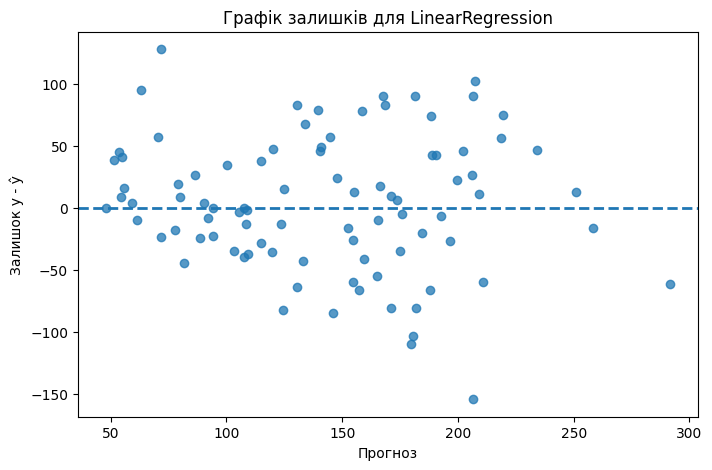

In [17]:
residuals = y_test - linear_pred

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--', linewidth=2)
plt.xlabel('Прогноз')
plt.ylabel('Залишок y - ŷ')
plt.title('Графік залишків для LinearRegression')
plt.show()

## 7. Недонавчання і перенавчання на поліноміальній регресії

Лінійна модель може недонавчатися, якщо реальна залежність нелінійна. Один зі способів збільшити гнучкість — створити поліноміальні ознаки. Але занадто високий ступінь полінома збільшує ризик перенавчання.

Порівняємо ступені 1, 4 і 15 на невеликій синтетичній вибірці.

In [18]:
rng = np.random.default_rng(RANDOM_STATE)
X_poly = np.sort(rng.uniform(-3, 3, 45)).reshape(-1, 1)
y_true_poly = np.sin(X_poly.ravel()) + 0.25 * X_poly.ravel()
y_poly = y_true_poly + rng.normal(0, 0.22, size=len(X_poly))

X_p_train, X_p_test, y_p_train, y_p_test = train_test_split(
    X_poly, y_poly, test_size=0.35, random_state=RANDOM_STATE
)

def fit_polynomial(degree):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression()),
    ])
    model.fit(X_p_train, y_p_train)
    train_pred = model.predict(X_p_train)
    test_pred = model.predict(X_p_test)
    return model, {
        'degree': degree,
        'train_rmse': root_mean_squared_error(y_p_train, train_pred),
        'test_rmse': root_mean_squared_error(y_p_test, test_pred),
    }

results = []
models_poly = {}
for degree in [1, 4, 15]:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)

pd.DataFrame(results)

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,4,0.144969,0.203183
2,15,0.091024,0.244266


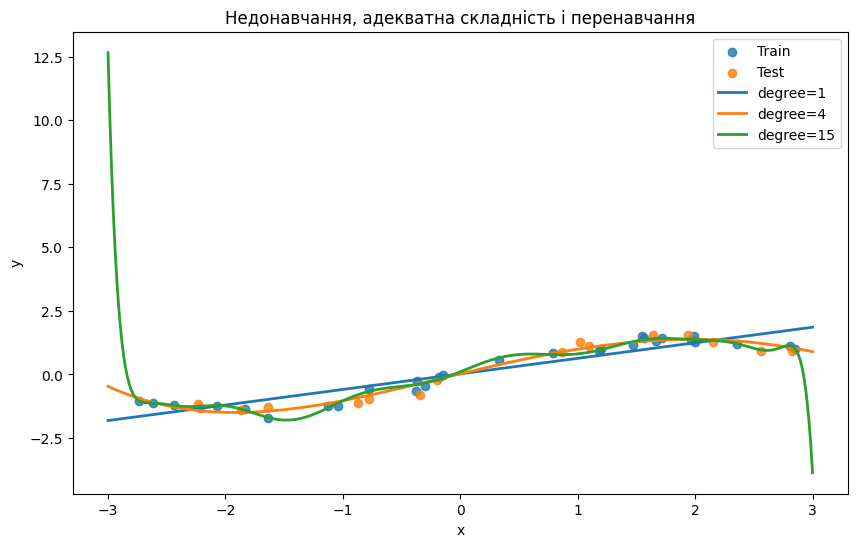

In [19]:
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_p_train, y_p_train, label='Train', alpha=0.8)
plt.scatter(X_p_test, y_p_test, label='Test', alpha=0.8)

for degree in [1, 4, 15]:
    plt.plot(grid, models_poly[degree].predict(grid), linewidth=2, label=f'degree={degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Недонавчання, адекватна складність і перенавчання')
plt.legend()
plt.show()

### Самостійне завдання 4

1. Додайте до порівняння ступені 2, 6 і 10.
2. Побудуйте таблицю `degree`, `train_rmse`, `test_rmse`.
3. Визначте ступінь із найменшим `test_rmse`.
4. Поясніть, чому мінімальна train-помилка не гарантує найкращої моделі.

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,2,0.392821,0.463992
2,4,0.144969,0.203183
3,6,0.137065,0.196267
4,10,0.129074,0.191782
5,15,0.091024,0.244266


Ступінь з найменшим test_rmse: 10 (test_rmse = 0.1918, train_rmse = 0.1291)
Ступінь з найменшим train_rmse: 15


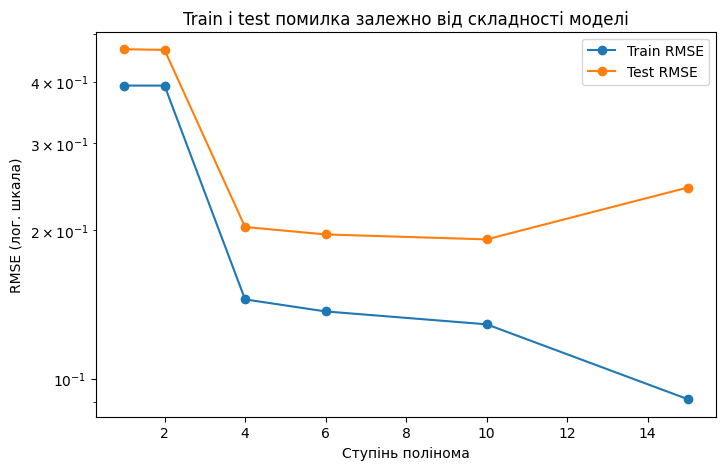

In [20]:
degrees_all = [1, 2, 4, 6, 10, 15]

rows = []
models_all = {}
for d in degrees_all:
    m, res = fit_polynomial(d)
    models_all[d] = m
    rows.append(res)

poly_table = pd.DataFrame(rows)
display(poly_table)

best_row = poly_table.loc[poly_table['test_rmse'].idxmin()]
print(f"Ступінь з найменшим test_rmse: {int(best_row['degree'])} "
      f"(test_rmse = {best_row['test_rmse']:.4f}, train_rmse = {best_row['train_rmse']:.4f})")
print(f"Ступінь з найменшим train_rmse: {int(poly_table.loc[poly_table['train_rmse'].idxmin(), 'degree'])}")

plt.figure(figsize=(8, 5))
plt.plot(poly_table['degree'], poly_table['train_rmse'], marker='o', label='Train RMSE')
plt.plot(poly_table['degree'], poly_table['test_rmse'], marker='o', label='Test RMSE')
plt.yscale('log')
plt.xlabel('Ступінь полінома')
plt.ylabel('RMSE (лог. шкала)')
plt.title('Train і test помилка залежно від складності моделі')
plt.legend()
plt.show()

Додаткова перевірка: у таблиці вище ознаки $x^{10}$, $x^{15}$ не масштабовані (значення сягають мільйонів), тому для ступеня 15 `LinearRegression` працює чисельно нестабільно. Додамо `StandardScaler` після `PolynomialFeatures` і подивимось на чисту картину перенавчання.

In [22]:
rows_scaled = []
for d in degrees_all:
    m = Pipeline([
        ('poly', PolynomialFeatures(degree=d, include_bias=False)),
        ('scale', StandardScaler()),
        ('reg', LinearRegression()),
    ]).fit(X_p_train, y_p_train)
    rows_scaled.append({
        'degree': d,
        'train_rmse': root_mean_squared_error(y_p_train, m.predict(X_p_train)),
        'test_rmse': root_mean_squared_error(y_p_test, m.predict(X_p_test)),
    })
display(pd.DataFrame(rows_scaled))

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,2,0.392821,0.463992
2,4,0.144969,0.203183
3,6,0.137065,0.196267
4,10,0.129074,0.191782
5,15,0.091024,0.244266


**Висновок до завдання 4:**

Найменший test_rmse (≈0.192) має ступінь 10, але ступені 4, 6 і 10 дають дуже близькі результати (≈0.203, 0.196, 0.192), а test складається лише з 16 точок, тому ця різниця в межах шуму; на практиці достатньо ступеня 4–6. Ступені 1 і 2 недонавчаються: і train, і test помилка висока (≈0.39 і ≈0.46), бо пряма/парабола не описує синусоїдальну залежність. У таблиці без масштабування train_rmse для ступеня 15 чомусь зростає — це чисельна нестабільність через величезні значення x¹⁵, а не ознака кращої моделі; у додатковій комірці зі StandardScaler видно класичне перенавчання: train_rmse для ступеня 15 найменший (≈0.09), а test_rmse (≈0.24) гірший, ніж у ступеня 10. Мінімальна train-помилка не гарантує найкращої моделі, бо train показує, наскільки добре модель підігналась під ті самі точки, включно з шумом: чим складніша модель, тим менша train-помилка, але гірше узагальнення. Якість потрібно оцінювати на даних, яких модель не бачила (test або крос-валідація).

## 8. Регуляризація: загальна ідея

Коли модель має багато ознак або ознаки сильно корельовані, коефіцієнти можуть ставати нестабільними. Регуляризація додає до функції втрат штраф за великі коефіцієнти.

Для **Ridge** використовується L2-штраф

$$\text{MSE}+\alpha\sum_{j=1}^{p} b_j^2,$$

для **Lasso** — L1-штраф

$$\text{MSE}+\alpha\sum_{j=1}^{p}|b_j|.$$

Параметр $\alpha$ керує силою регуляризації. Якщо $\alpha=0$, штраф зникає. Надто велике $\alpha$ може надмірно стиснути коефіцієнти й спричинити недонавчання.

## 9. Чому перед Ridge, Lasso та Elastic Net потрібне масштабування

In [23]:
# Штучно змінюємо масштаби кількох ознак, щоб побачити роль StandardScaler.
X_scaled_demo = X.copy()
X_scaled_demo['bmi'] = X_scaled_demo['bmi'] * 1000
X_scaled_demo['bp'] = X_scaled_demo['bp'] * 0.01

Xsd_train, Xsd_test, ysd_train, ysd_test = train_test_split(
    X_scaled_demo, y, test_size=0.2, random_state=RANDOM_STATE
)

ridge_no_scaling = Ridge(alpha=10.0).fit(Xsd_train, ysd_train)
ridge_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(Xsd_train, ysd_train)

print('Ridge без масштабування RMSE:', root_mean_squared_error(ysd_test, ridge_no_scaling.predict(Xsd_test)))
print('Ridge + StandardScaler RMSE:', root_mean_squared_error(ysd_test, ridge_pipeline.predict(Xsd_test)))

Ridge без масштабування RMSE: 62.25349241861679
Ridge + StandardScaler RMSE: 53.626287568895194


Штраф застосовується безпосередньо до коефіцієнтів. Якщо ознаки вимірюються в дуже різних масштабах, одна й та сама величина коефіцієнта не має однакового змісту. Тому `StandardScaler` зазвичай включають у `Pipeline` перед регуляризованою лінійною моделлю.

## 10. Ridge-регресія: L2-регуляризація

In [24]:
ridge = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

print(regression_metrics(y_test, ridge_pred))

{'MAE': 42.81199941834889, 'MSE': 2892.0145657501726, 'RMSE': 53.777454065343896, 'R2': 0.45414652070698225, 'MAPE': np.float64(37.44816405198748)}


## 11. Lasso: L1-регуляризація

In [25]:
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=1.0, max_iter=20000)),
])

lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

lasso_coef = lasso.named_steps['reg'].coef_
print(regression_metrics(y_test, lasso_pred))
print('Кількість нульових коефіцієнтів:', np.sum(np.isclose(lasso_coef, 0)))

{'MAE': 42.80298373195777, 'MSE': 2824.568094049959, 'RMSE': 53.14666587896139, 'R2': 0.46687670944102466, 'MAPE': np.float64(37.43982076869067)}
Кількість нульових коефіцієнтів: 1


На відміну від Ridge, Lasso може занулювати частину коефіцієнтів. Саме тому L1-регуляризацію іноді використовують як вбудований механізм відбору ознак. Проте при сильно корельованих предикторах вибір конкретної ознаки може бути нестабільним.

## 12. Elastic Net: поєднання L1 та L2

In [26]:
elastic = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
])

elastic.fit(X_train, y_train)
elastic_pred = elastic.predict(X_test)

print(regression_metrics(y_test, elastic_pred))

{'MAE': 42.873332243316874, 'MSE': 2866.4612552977674, 'RMSE': 53.539343060013046, 'R2': 0.4589695819678379, 'MAPE': np.float64(37.40678706534485)}


В Elastic Net параметр `alpha` визначає загальну силу регуляризації, а `l1_ratio` — співвідношення між L1 та L2. Значення `l1_ratio=1` наближає модель до Lasso, а `l1_ratio=0` — до Ridge.

### Самостійне завдання 5

Навчіть на одному й тому самому train/test розбитті чотири моделі: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`. Для регуляризованих моделей використайте `StandardScaler` у `Pipeline`. Побудуйте таблицю з MAE, RMSE та $R^2$.

In [27]:
models_t5 = {
    'LinearRegression': LinearRegression(),
    'Ridge': Pipeline([('scale', StandardScaler()), ('reg', Ridge(alpha=1.0))]),
    'Lasso': Pipeline([('scale', StandardScaler()), ('reg', Lasso(alpha=1.0, max_iter=20000))]),
    'ElasticNet': Pipeline([('scale', StandardScaler()),
                            ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000))]),
}

rows_t5 = {}
for name, mdl in models_t5.items():
    mdl.fit(X_train, y_train)
    pred = mdl.predict(X_test)
    rows_t5[name] = {
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': root_mean_squared_error(y_test, pred),
        'R2': r2_score(y_test, pred),
    }

task5_table = pd.DataFrame(rows_t5).T
display(task5_table.sort_values('RMSE'))

,MAE,RMSE,R2
Lasso,42.802984,53.146666,0.466877
ElasticNet,42.873332,53.539343,0.458970
Ridge,42.811999,53.777454,0.454147
LinearRegression,42.794095,53.853446,0.452603


**Висновок до завдання 5:** найменші помилки на test у Lasso (RMSE ≈ 53.15, R² ≈ 0.467), найбільші — у звичайної LinearRegression (RMSE ≈ 53.85, R² ≈ 0.453), але різниця між усіма чотирма моделями дуже мала (менше 1.5% за RMSE). Причина в тому, що в наборі diabetes лише 10 ознак і досить багато об'єктів, тож регуляризація дає лише невеликий виграш. Порядок моделей на одному test-розбитті ненадійний, тому порівняння продовжуємо через крос-валідацію.

## 13. Крос-валідація

Одне train/test розбиття залежить від випадкового поділу. K-fold cross-validation кілька разів змінює validation-частину і дає більш стійку оцінку якості моделі. Важливо, що preprocessing повинен бути всередині `Pipeline`, щоб на кожному фолді параметри масштабування оцінювалися лише з train-частини.

In [28]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_cv_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

scores = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    return_train_score=True,
)

cv_table = pd.DataFrame({
    'fold': np.arange(1, 6),
    'train_R2': scores['train_r2'],
    'val_R2': scores['test_r2'],
    'val_MAE': -scores['test_mae'],
    'val_RMSE': -scores['test_rmse'],
})

display(cv_table)
print('Середній validation RMSE:', cv_table['val_RMSE'].mean())

,fold,train_R2,val_R2,val_MAE,val_RMSE
0,1,0.527632,0.454147,42.811999,53.777454
1,2,0.497124,0.571674,41.616638,51.692906
2,3,0.538901,0.391921,47.224871,57.530264
3,4,0.494045,0.583169,42.166318,52.966248
4,5,0.540152,0.394449,47.397540,58.168400


Середній validation RMSE: 54.827054212084306


## 14. Підбір alpha для Ridge за GridSearchCV

In [29]:
ridge_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])

param_grid_ridge = {
    'reg__alpha': np.logspace(0, 5, 13)
}

ridge_search = GridSearchCV(
    ridge_search_model,
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)

print('Найкраще alpha:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE:', -ridge_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, ridge_search.predict(X_test)))

Найкраще alpha: 1.0
CV RMSE: 55.374175368673455
Test RMSE: 53.777454065343896


Тестову вибірку не використовують для підбору `alpha`. Гіперпараметр обирається всередині train за крос-валідацією, а test використовується лише після завершення вибору моделі.

## 15. Підбір alpha і l1_ratio для Elastic Net

In [30]:
elastic_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

elastic_search = GridSearchCV(
    elastic_search_model,
    param_grid=param_grid_elastic,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

elastic_search.fit(X_train, y_train)

print('Найкращі параметри:', elastic_search.best_params_)
print('CV RMSE:', -elastic_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, elastic_search.predict(X_test)))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test RMSE: 53.74450007977087


### Самостійне завдання 6

Виконайте `GridSearchCV` для Lasso. Перевірте не менше 10 значень `alpha` у логарифмічній шкалі. Порівняйте найкращий Lasso з найкращим Ridge за однаковою схемою CV.

In [31]:
lasso_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(max_iter=50000)),
])

param_grid_lasso = {
    'reg__alpha': np.logspace(-3, 2, 13)
}

lasso_search = GridSearchCV(
    lasso_search_model,
    param_grid=param_grid_lasso,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)
lasso_search.fit(X_train, y_train)

lasso_best_coef = lasso_search.best_estimator_.named_steps['reg'].coef_
cmp_t6 = pd.DataFrame({
    'best_alpha': [ridge_search.best_params_['reg__alpha'], lasso_search.best_params_['reg__alpha']],
    'CV_RMSE': [-ridge_search.best_score_, -lasso_search.best_score_],
    'Test_RMSE': [root_mean_squared_error(y_test, ridge_search.predict(X_test)),
                  root_mean_squared_error(y_test, lasso_search.predict(X_test))],
}, index=['Ridge', 'Lasso'])
display(cmp_t6)
print('Нульових коефіцієнтів у найкращого Lasso:', int(np.sum(np.isclose(lasso_best_coef, 0))), 'з', len(lasso_best_coef))

,best_alpha,CV_RMSE,Test_RMSE
Ridge,1.000000,55.374175,53.777454
Lasso,0.121153,55.351920,53.694850


Нульових коефіцієнтів у найкращого Lasso: 1 з 10


**Висновок до завдання 6:** найкращий Lasso має alpha ≈ 0.12 (CV RMSE ≈ 55.352, test RMSE ≈ 53.695), найкращий Ridge — alpha = 1.0 (CV RMSE ≈ 55.374, test RMSE ≈ 53.777). Lasso формально трохи кращий, але різниця у CV RMSE (≈0.02) значно менша за розкид між фолдами (≈2.4), тому за якістю ці моделі практично рівноцінні. Lasso при цьому занулює одну ознаку з десяти, тож дає трохи простішу модель. Для Ridge сітка викладача починається з alpha = 1, але в підсумковому завданні сітка сягає 1e-3, і найкращим усе одно виявляється alpha = 1, тобто оптимум Ridge справді поблизу 1.

## 16. Як регуляризація змінює коефіцієнти

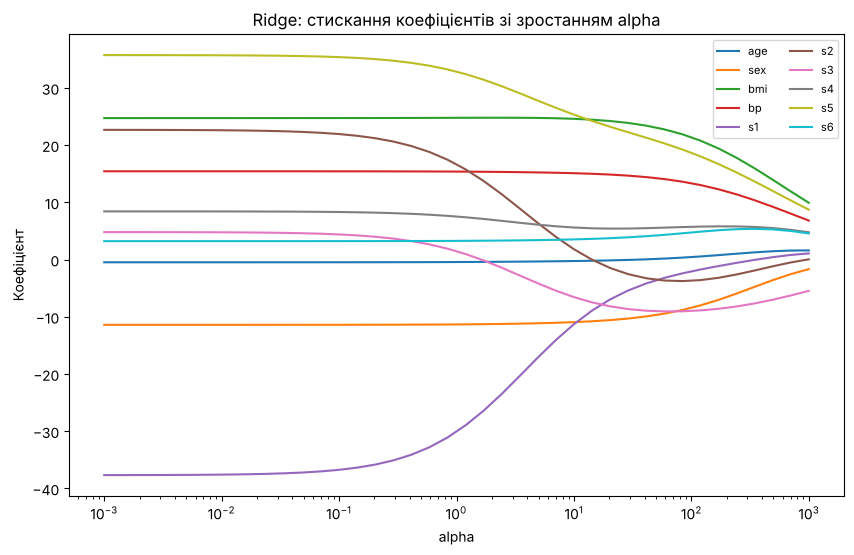

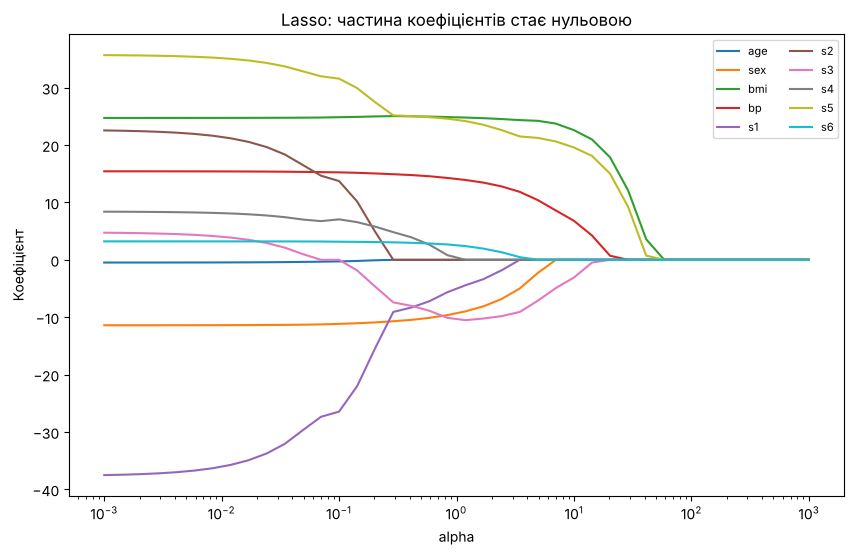

In [ ]:
alphas = np.logspace(-3, 3, 40)
ridge_paths = []
lasso_paths = []

X_for_path = StandardScaler().fit_transform(X)

for alpha in alphas:
    ridge_m = Ridge(alpha=alpha).fit(X_for_path, y)
    lasso_m = Lasso(alpha=alpha, max_iter=30000).fit(X_for_path, y)
    ridge_paths.append(ridge_m.coef_)
    lasso_paths.append(lasso_m.coef_)

ridge_paths = np.array(ridge_paths)
lasso_paths = np.array(lasso_paths)

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, ridge_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Ridge: стискання коефіцієнтів зі зростанням alpha')
plt.legend(ncol=2, fontsize=8)
plt.show()

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, lasso_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Lasso: частина коефіцієнтів стає нульовою')
plt.legend(ncol=2, fontsize=8)
plt.show()

Ці графіки демонструють ключову різницю. Ridge плавно стискає коефіцієнти до нуля, тоді як Lasso може зробити частину з них точно нульовими.

## 17. Мультиколінеарність і стабільність коефіцієнтів

In [32]:
rng = np.random.default_rng(RANDOM_STATE)
n = 250
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.03, size=n)  # дуже сильна кореляція
x3 = rng.normal(size=n)
y_corr = 5 * x1 + 5 * x2 + 0.5 * x3 + rng.normal(scale=1.5, size=n)

X_corr = pd.DataFrame({'x1': x1, 'x2': x2, 'x3': x3})
print(X_corr.corr())

ols_corr = LinearRegression().fit(X_corr, y_corr)
ridge_corr = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(X_corr, y_corr)

coef_compare = pd.DataFrame({
    'feature': X_corr.columns,
    'OLS': ols_corr.coef_,
    'Ridge_scaled': ridge_corr.named_steps['reg'].coef_,
})
coef_compare

          x1        x2        x3
x1  1.000000  0.999515 -0.008921
x2  0.999515  1.000000 -0.010420
x3 -0.008921 -0.010420  1.000000


,feature,OLS,Ridge_scaled
0,x1,5.446248,4.546617
1,x2,4.410887,4.534370
2,x3,0.444792,0.439193


За наявності дуже корельованих ознак окремі коефіцієнти OLS можуть бути нестабільними: невеликі зміни даних здатні суттєво змінити їх значення. Ridge зменшує variance коефіцієнтів завдяки L2-штрафу.

## 18. Категоріальні ознаки, пропуски та ColumnTransformer

У реальній табличній задачі дані часто містять числові й категоріальні ознаки, а також пропуски. Їх потрібно обробляти всередині `Pipeline`, щоб не створювати витік інформації.

In [33]:
rng = np.random.default_rng(RANDOM_STATE)
n = 300

housing = pd.DataFrame({
    'area': rng.normal(75, 20, n).clip(25, 150),
    'rooms': rng.integers(1, 6, n),
    'age': rng.integers(0, 70, n).astype(float),
    'district': rng.choice(['center', 'north', 'south'], n, p=[0.3, 0.35, 0.35]),
})

# Додаємо кілька пропусків.
housing.loc[rng.choice(n, 18, replace=False), 'age'] = np.nan

price = (
    1500 * housing['area']
    + 7000 * housing['rooms']
    - 500 * housing['age'].fillna(housing['age'].median())
    + housing['district'].map({'center': 40000, 'north': 12000, 'south': 0})
    + rng.normal(0, 12000, n)
)

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ['area', 'rooms', 'age']
categorical_features = ['district']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

housing_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

housing_model.fit(X_h_train, y_h_train)
housing_pred = housing_model.predict(X_h_test)

print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred))
print('Housing R2:', r2_score(y_h_test, housing_pred))
print('Housing MAE:', mean_absolute_error(y_h_test, housing_pred))
print('MAPE', mean_absolute_percentage_error(y_h_test, housing_pred))

Housing RMSE: 10925.278371503928
Housing R2: 0.9068908686435069
Housing MAE: 8737.023097309464
MAPE 0.07276440135248957


In [35]:
housing

,area,rooms,age,district
0,81.094342,4,17.0,south
1,54.200318,2,66.0,south
2,90.009024,2,37.0,center
3,93.811294,2,21.0,south
4,35.979296,3,29.0,south
...,...,...,...,...
295,78.530248,4,30.0,center
296,80.919880,5,45.0,center
297,67.561708,3,38.0,center
298,39.865564,3,67.0,south


In [34]:
price

,0
0,146888.018855
1,43872.771974
2,175189.836338
3,145447.579696
4,58699.634461
...,...
295,179796.834387
296,197085.341513
297,166868.377770
298,32562.347956


### Самостійне завдання 7

Додайте до таблиці `housing` нову категоріальну ознаку `condition` зі значеннями `new`, `good`, `needs_repair`. Включіть її в `ColumnTransformer`, перенавчіть модель і перевірте, чи змінилася test-помилка.

In [36]:
rng_cond = np.random.default_rng(RANDOM_STATE + 1)
housing2 = housing.copy()
housing2['condition'] = rng_cond.choice(['new', 'good', 'needs_repair'], len(housing2), p=[0.25, 0.5, 0.25])
print(housing2['condition'].value_counts())

X_h2_train, X_h2_test, y_h2_train, y_h2_test = train_test_split(
    housing2, price, test_size=0.2, random_state=RANDOM_STATE
)

categorical_features2 = ['district', 'condition']

preprocessor2 = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features2),
])

housing_model2 = Pipeline([
    ('prep', preprocessor2),
    ('reg', Ridge(alpha=1.0)),
])
housing_model2.fit(X_h2_train, y_h2_train)
housing_pred2 = housing_model2.predict(X_h2_test)

cmp_t7 = pd.DataFrame({
    'RMSE': [root_mean_squared_error(y_h_test, housing_pred), root_mean_squared_error(y_h2_test, housing_pred2)],
    'MAE': [mean_absolute_error(y_h_test, housing_pred), mean_absolute_error(y_h2_test, housing_pred2)],
    'R2': [r2_score(y_h_test, housing_pred), r2_score(y_h2_test, housing_pred2)],
}, index=['без condition', 'з condition'])
cmp_t7['ΔRMSE'] = cmp_t7['RMSE'] - cmp_t7.loc['без condition', 'RMSE']
display(cmp_t7)

condition
good            153
needs_repair     75
new              72
Name: count, dtype: int64


,RMSE,MAE,R2,ΔRMSE
без condition,10925.278372,8737.023097,0.906891,0.000000
з condition,10870.176194,8711.883272,0.907828,-55.102178


**Висновок до завдання 7:** test-помилка майже не змінилась: RMSE зменшилась з ≈10 925 до ≈10 870 (≈0.5%), R² — з 0.9069 до 0.9078. Це пояснюється тим, що ознака condition згенерована випадково й не впливає на ціну (price сформована без неї), тож модель не отримала корисної нової інформації, а мікроскопічну різницю слід вважати випадковою, а не ефектом ознаки. Якби стан квартири реально впливав на ціну, додавання condition помітно зменшило б помилку. Сам код при цьому показує, як у ColumnTransformer додається нова категоріальна ознака: достатньо дописати її назву до списку categorical_features.

## 19. Навчальні криві

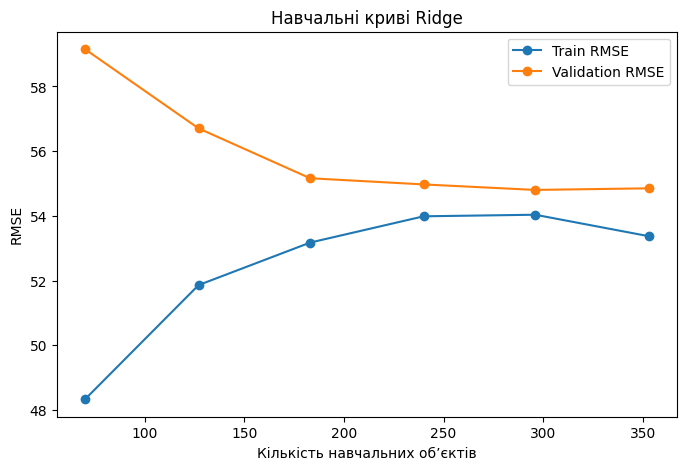

In [37]:
learning_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=ridge_search.best_params_['reg__alpha'])),
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_model,
    X,
    y,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
)

train_rmse_curve = -train_scores.mean(axis=1)
val_rmse_curve = -val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse_curve, marker='o', label='Train RMSE')
plt.plot(train_sizes, val_rmse_curve, marker='o', label='Validation RMSE')
plt.xlabel('Кількість навчальних об’єктів')
plt.ylabel('RMSE')
plt.title('Навчальні криві Ridge')
plt.legend()
plt.show()

Якщо train і validation помилки високі та близькі, це ознака можливого недонавчання. Якщо train-помилка значно нижча за validation, це може свідчити про високу variance та перенавчання. Навчальні криві допомагають зрозуміти, чи може збільшення обсягу даних бути корисним.

## 20. Повний приклад: коректний вибір моделі без використання test

In [38]:
# 1. Test відкладаємо один раз.
X_final_train, X_final_test, y_final_train, y_final_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# 2. Вибір моделі відбувається тільки всередині train за CV.
model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.5, 0.9],
}

search = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=cv,
    n_jobs=-1,
)
search.fit(X_final_train, y_final_train)

# 3. Лише після завершення підбору оцінюємо test.
final_pred = search.predict(X_final_test)

print('Найкращі параметри:', search.best_params_)
print('CV RMSE:', -search.best_score_)
print('Test metrics:', regression_metrics(y_final_test, final_pred))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test metrics: {'MAE': 42.81393247843441, 'MSE': 2888.4712888244917, 'RMSE': 53.74450007977087, 'R2': 0.4548152967432053, 'MAPE': np.float64(37.42858410670238)}


## 21. Підсумкове практичне завдання для самостійної роботи

Виконайте повний експеримент на наборі `diabetes`. Цей блок потрібно зробити самостійно, використовуючи попередні приклади лише як орієнтир.

**Вимоги до роботи:**

1. Завантажити `load_diabetes(as_frame=True)` і переглянути структуру даних.
2. Відкласти 20% даних у test із `random_state=42`.
3. Побудувати `DummyRegressor` і `LinearRegression` як baseline.
4. Обчислити MAE, RMSE та $R^2$ на test.
5. Побудувати Ridge, Lasso та Elastic Net через `Pipeline` із `StandardScaler`.
6. Виконати 5-fold cross-validation.
7. Для Ridge і Lasso підібрати `alpha`; для Elastic Net — `alpha` та `l1_ratio`.
8. Порівняти моделі в одній таблиці.
9. Для найкращої моделі побудувати графік фактичні значення → прогноз та графік залишків.
10. Проаналізувати коефіцієнти найкращої лінійної моделі.
11. Сформулювати підсумковий висновок: яка модель обрана, за якою метрикою та чому.

Нижче залишені окремі комірки для кожного етапу.

### Крок 1. Дані

In [39]:
diabetes_task = load_diabetes(as_frame=True)
X_task = diabetes_task.data.copy()
y_task = diabetes_task.target.copy()

print('X_task shape:', X_task.shape)
print('y_task shape:', y_task.shape)
print('Пропуски в X:', int(X_task.isna().sum().sum()), '| у y:', int(y_task.isna().sum()))
display(X_task.head())
display(y_task.describe().to_frame('target'))

X_task shape: (442, 10)
y_task shape: (442,)
Пропуски в X: 0 | у y: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,target
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


### Крок 2. Train/test

In [40]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X_task, y_task, test_size=0.2, random_state=42
)
print('Train:', X_tr.shape, '| Test:', X_te.shape)

Train: (353, 10) | Test: (89, 10)


### Крок 3. Baseline

In [42]:
dummy_task = DummyRegressor(strategy='mean').fit(X_tr, y_tr)
lin_task = LinearRegression().fit(X_tr, y_tr)

dummy_pred_task = dummy_task.predict(X_te)
lin_pred_task = lin_task.predict(X_te)

### Крок 4. Метрики

In [43]:
def test_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
    }

baseline_table = pd.DataFrame(
    [test_metrics(y_te, dummy_pred_task), test_metrics(y_te, lin_pred_task)],
    index=['DummyRegressor', 'LinearRegression']
)
display(baseline_table)

,MAE,RMSE,R2
DummyRegressor,64.006461,73.222493,-0.011963
LinearRegression,42.794095,53.853446,0.452603


### Крок 5. Ridge, Lasso, Elastic Net

In [44]:
ridge_task = Pipeline([('scale', StandardScaler()), ('reg', Ridge(alpha=1.0))])
lasso_task = Pipeline([('scale', StandardScaler()), ('reg', Lasso(alpha=1.0, max_iter=50000))])
enet_task = Pipeline([('scale', StandardScaler()),
                      ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=50000))])

for mdl in (ridge_task, lasso_task, enet_task):
    mdl.fit(X_tr, y_tr)

reg_untuned = pd.DataFrame({
    'Ridge (alpha=1)': test_metrics(y_te, ridge_task.predict(X_te)),
    'Lasso (alpha=1)': test_metrics(y_te, lasso_task.predict(X_te)),
    'ElasticNet (alpha=0.1, l1=0.5)': test_metrics(y_te, enet_task.predict(X_te)),
}).T
display(reg_untuned)

,MAE,RMSE,R2
Ridge (alpha=1),42.811999,53.777454,0.454147
Lasso (alpha=1),42.802984,53.146666,0.466877
"ElasticNet (alpha=0.1, l1=0.5)",42.873332,53.539343,0.458970


### Крок 6. Крос-валідація

In [45]:
cv_task = KFold(n_splits=5, shuffle=True, random_state=42)

models_cv = {
    'DummyRegressor': DummyRegressor(strategy='mean'),
    'LinearRegression': LinearRegression(),
    'Ridge (alpha=1)': ridge_task,
    'Lasso (alpha=1)': lasso_task,
    'ElasticNet (alpha=0.1, l1=0.5)': enet_task,
}

cv_rows = {}
for name, mdl in models_cv.items():
    sc = cross_validate(mdl, X_tr, y_tr, cv=cv_task,
                        scoring='neg_root_mean_squared_error', return_train_score=True)
    cv_rows[name] = {
        'train_RMSE': -sc['train_score'].mean(),
        'CV_RMSE': -sc['test_score'].mean(),
        'CV_RMSE_std': sc['test_score'].std(),
    }

cv_untuned = pd.DataFrame(cv_rows).T
display(cv_untuned.sort_values('CV_RMSE'))

,train_RMSE,CV_RMSE,CV_RMSE_std
Ridge (alpha=1),53.370264,55.374175,2.373206
Lasso (alpha=1),53.659439,55.388472,2.324856
LinearRegression,53.346125,55.394633,2.361496
"ElasticNet (alpha=0.1, l1=0.5)",53.600328,55.433157,2.351324
DummyRegressor,77.898116,78.133634,5.638302


### Крок 7. Підбір гіперпараметрів

In [46]:
searches = {
    'Ridge': GridSearchCV(
        Pipeline([('scale', StandardScaler()), ('reg', Ridge())]),
        {'reg__alpha': np.logspace(-3, 3, 25)},
        cv=cv_task, scoring='neg_root_mean_squared_error', n_jobs=-1),
    'Lasso': GridSearchCV(
        Pipeline([('scale', StandardScaler()), ('reg', Lasso(max_iter=50000))]),
        {'reg__alpha': np.logspace(-3, 2, 25)},
        cv=cv_task, scoring='neg_root_mean_squared_error', n_jobs=-1),
    'ElasticNet': GridSearchCV(
        Pipeline([('scale', StandardScaler()), ('reg', ElasticNet(max_iter=50000))]),
        {'reg__alpha': np.logspace(-3, 1, 13),
         'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0]},
        cv=cv_task, scoring='neg_root_mean_squared_error', n_jobs=-1),
}

for name, gs in searches.items():
    gs.fit(X_tr, y_tr)
    print(f'{name:<11} найкращі параметри: {gs.best_params_} | CV RMSE = {-gs.best_score_:.3f}')

Ridge       найкращі параметри: {'reg__alpha': np.float64(1.0)} | CV RMSE = 55.374
Lasso       найкращі параметри: {'reg__alpha': np.float64(0.510896977450693)} | CV RMSE = 55.351
ElasticNet  найкращі параметри: {'reg__alpha': np.float64(0.1), 'reg__l1_ratio': 1.0} | CV RMSE = 55.354


### Крок 8. Фінальна таблиця моделей

In [48]:
final_models = {
    'DummyRegressor': DummyRegressor(strategy='mean').fit(X_tr, y_tr),
    'LinearRegression': LinearRegression().fit(X_tr, y_tr),
    'Ridge (tuned)': searches['Ridge'].best_estimator_,
    'Lasso (tuned)': searches['Lasso'].best_estimator_,
    'ElasticNet (tuned)': searches['ElasticNet'].best_estimator_,
}

cv_rmse_map = {
    'DummyRegressor': -cross_validate(DummyRegressor(), X_tr, y_tr, cv=cv_task,
                                      scoring='neg_root_mean_squared_error')['test_score'].mean(),
    'LinearRegression': -cross_validate(LinearRegression(), X_tr, y_tr, cv=cv_task,
                                        scoring='neg_root_mean_squared_error')['test_score'].mean(),
    'Ridge (tuned)': -searches['Ridge'].best_score_,
    'Lasso (tuned)': -searches['Lasso'].best_score_,
    'ElasticNet (tuned)': -searches['ElasticNet'].best_score_,
}

rows_final = []
for name, mdl in final_models.items():
    m = test_metrics(y_te, mdl.predict(X_te))
    rows_final.append({
        'model': name,
        'CV_RMSE': cv_rmse_map[name],
        'test_MAE': m['MAE'],
        'test_RMSE': m['RMSE'],
        'test_R2': m['R2'],
    })

final_table = pd.DataFrame(rows_final).set_index('model')
display(final_table.sort_values('CV_RMSE'))

best_name = final_table['CV_RMSE'].idxmin()
print('Обрана модель (мінімум CV RMSE):', best_name)
best_model = final_models[best_name]

,CV_RMSE,test_MAE,test_RMSE,test_R2
model,,,,
Lasso (tuned),55.350604,42.838671,53.447812,0.460818
ElasticNet (tuned),55.353958,42.805234,53.708698,0.455541
Ridge (tuned),55.374175,42.811999,53.777454,0.454147
LinearRegression,55.394633,42.794095,53.853446,0.452603
DummyRegressor,78.133634,64.006461,73.222493,-0.011963


Обрана модель (мінімум CV RMSE): Lasso (tuned)


### Крок 9. Візуалізація найкращої моделі

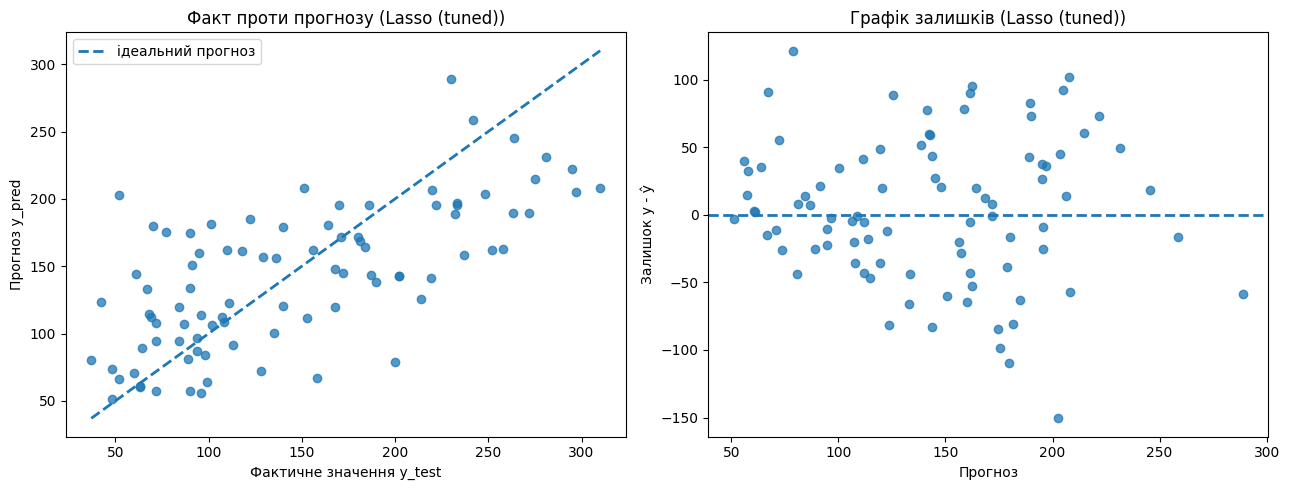

In [49]:
best_pred = best_model.predict(X_te)
best_resid = y_te - best_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_te, best_pred, alpha=0.75)
lims = [min(y_te.min(), best_pred.min()), max(y_te.max(), best_pred.max())]
axes[0].plot(lims, lims, linestyle='--', linewidth=2, label='ідеальний прогноз')
axes[0].set_xlabel('Фактичне значення y_test')
axes[0].set_ylabel('Прогноз y_pred')
axes[0].set_title(f'Факт проти прогнозу ({best_name})')
axes[0].legend()

axes[1].scatter(best_pred, best_resid, alpha=0.75)
axes[1].axhline(0, linestyle='--', linewidth=2)
axes[1].set_xlabel('Прогноз')
axes[1].set_ylabel('Залишок y - ŷ')
axes[1].set_title(f'Графік залишків ({best_name})')

plt.tight_layout()
plt.show()

### Крок 10. Коефіцієнти

,feature,coefficient,abs_coefficient
0,bmi,26.225969,26.225969
1,s5,23.074963,23.074963
2,bp,16.157722,16.157722
3,s1,-11.587822,11.587822
4,sex,-10.366915,10.366915
5,s4,7.365915,7.365915
6,s3,-6.489456,6.489456
7,s6,2.324523,2.324523
8,age,1.327926,1.327926
9,s2,0.000000,0.000000


Intercept: 153.737


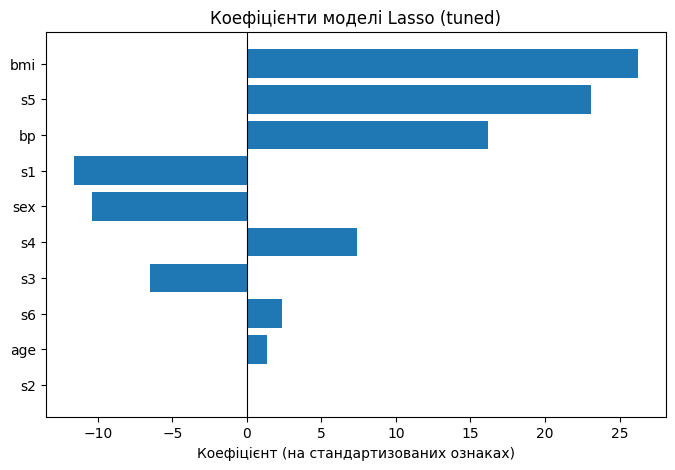

In [50]:
reg_step = best_model.named_steps['reg'] if hasattr(best_model, 'named_steps') else best_model
coef_best = pd.DataFrame({
    'feature': X_task.columns,
    'coefficient': reg_step.coef_,
})
coef_best['abs_coefficient'] = coef_best['coefficient'].abs()
coef_best = coef_best.sort_values('abs_coefficient', ascending=False).reset_index(drop=True)
display(coef_best)
print('Intercept:', round(float(reg_step.intercept_), 3))

plt.figure(figsize=(8, 5))
plt.barh(coef_best['feature'][::-1], coef_best['coefficient'][::-1])
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Коефіцієнт (на стандартизованих ознаках)')
plt.title(f'Коефіцієнти моделі {best_name}')
plt.show()

### Крок 11. Підсумковий висновок

За мінімумом CV RMSE обрано Lasso з alpha ≈ 0.51 (CV RMSE ≈ 55.35); на test вона дала MAE ≈ 42.8, RMSE ≈ 53.4 та R² ≈ 0.46. Вибір зроблено саме за CV RMSE, бо RMSE вимірюється в одиницях цільової змінної та сильніше карає великі помилки, а крос-валідація стабільніша за одне випадкове розбиття. Baseline DummyRegressor суттєво гірший (RMSE ≈ 73.2, R² ≈ −0.01), тож лінійні моделі справді знаходять закономірності в ознаках. Сильного перенавчання немає: train RMSE ≈ 53.6, CV RMSE ≈ 55.4, test RMSE ≈ 53.4, тобто розрив невеликий, а помірний R² ≈ 0.46 свідчить скоріше про обмеженість лінійної моделі й шум у даних, ніж про перенавчання. Регуляризація дала лише мізерний виграш: CV RMSE становить ≈55.39 для LinearRegression, ≈55.37 для Ridge і ≈55.35 для Lasso, а ця різниця набагато менша за розкид між фолдами (≈2.4), тому за якістю моделі практично рівноцінні, а перевага Lasso — у простішій інтерпретації (вона занулила ознаку s2). Test не використовувався для підбору alpha та l1_ratio і для вибору моделі, щоб він залишився незалежною оцінкою якості: якби гіперпараметри підбирались за test, інформація з нього «просочилась» би у модель, і результат був би оптимістично завищеним.